In [3]:
import pandas as pd

df = pd.read_csv("cleaned_dataset.csv")

print("Dataset loaded successfully!")
print(df.head())
print(df.columns)

Dataset loaded successfully!
  code_module code_presentation  id_student gender                region  \
0         AAA             2013J     11391.0      M   East Anglian Region   
1         AAA             2013J     28400.0      F              Scotland   
2         AAA             2013J     30268.0      F  North Western Region   
3         AAA             2013J     31604.0      F     South East Region   
4         AAA             2013J     32885.0      F  West Midlands Region   

       highest_education imd_band age_band  num_of_prev_attempts  \
0       HE Qualification  90-100%     55<=                   0.0   
1       HE Qualification   20-30%    35-55                   0.0   
2  A Level or Equivalent   30-40%    35-55                   0.0   
3  A Level or Equivalent   50-60%    35-55                   0.0   
4     Lower Than A Level   50-60%     0-35                   0.0   

   studied_credits disability final_result  
0            240.0          N         Pass  
1             6

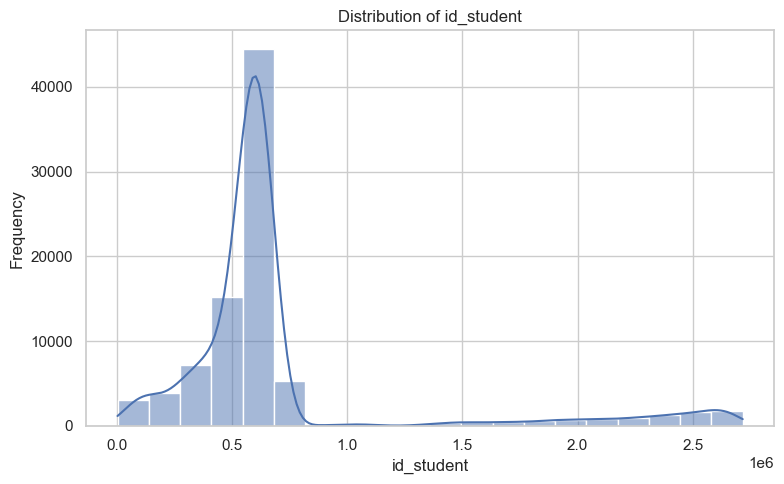

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

numeric_cols = df.select_dtypes(
    include="number"
).columns

if len(numeric_cols) > 0:
    col = numeric_cols[0]

    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

else:
    print("No numerical columns available.")

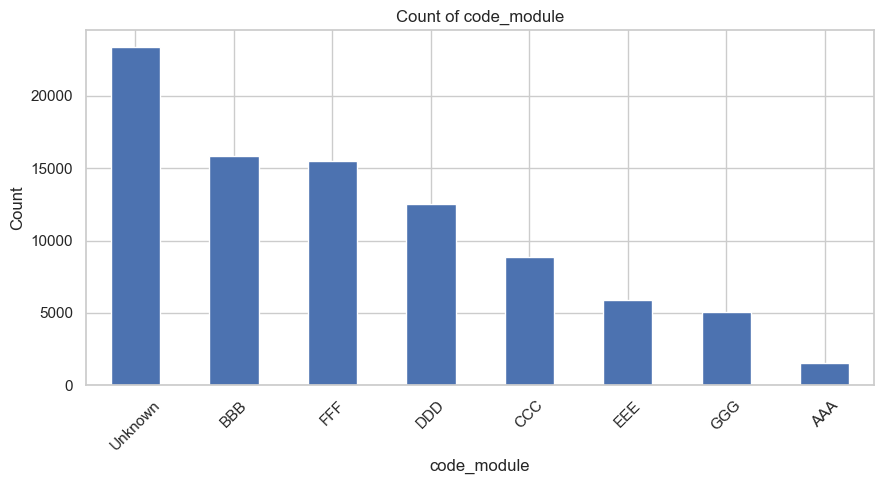

In [5]:

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

if len(categorical_cols) > 0:
    col = categorical_cols[0]

    counts = df[col].value_counts().head(10)

    plt.figure(figsize=(9, 5))
    counts.plot(kind="bar")
    plt.title(f"Count of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns available.")

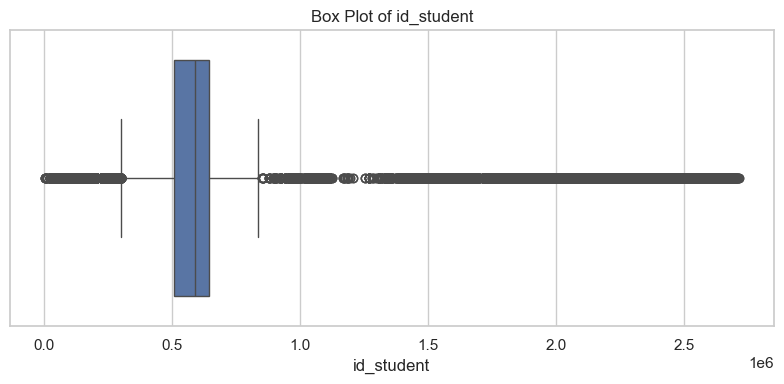

In [6]:

if len(numeric_cols) > 0:
    col = numeric_cols[0]

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x=col)
    plt.title(f"Box Plot of {col}")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns available.")

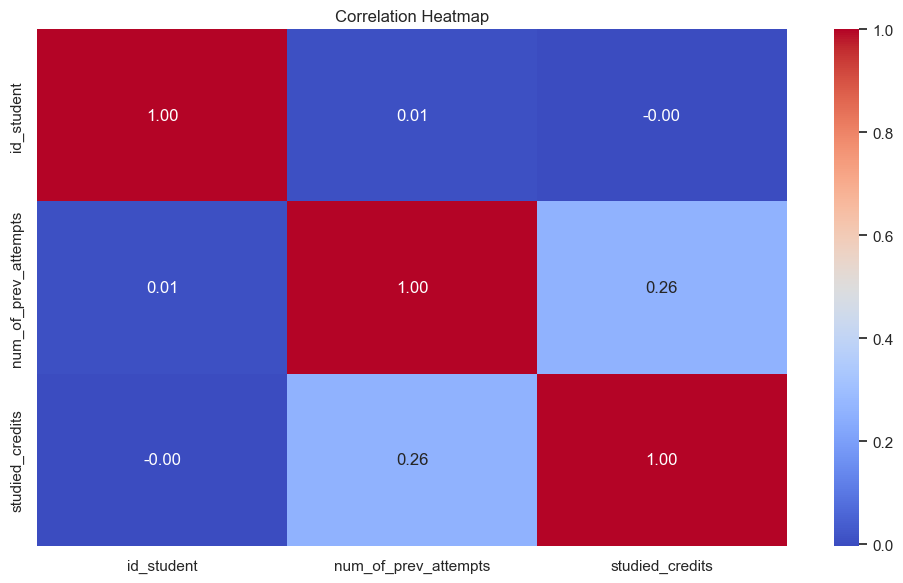

In [7]:

if len(numeric_cols) >= 2:
    correlation = df[numeric_cols].corr()

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required.")

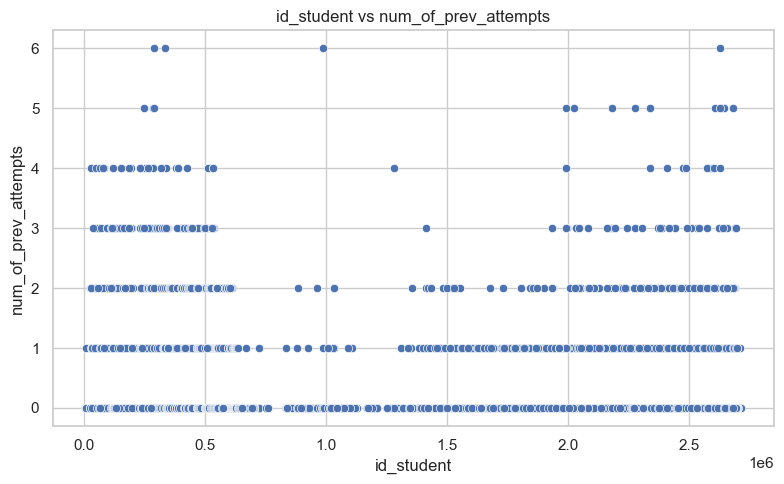

In [8]:

if len(numeric_cols) >= 2:
    x_col = numeric_cols[0]
    y_col = numeric_cols[1]

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col)
    plt.title(f"{x_col} vs {y_col}")
    plt.tight_layout()
    plt.show()
else:
    print("Two numerical columns are required.")

In [9]:

print("PROJECT DATA ANALYSIS REPORT")
print("-" * 35)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nNumerical Columns:")
print(numeric_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())

if len(numeric_cols) > 0:
    print("\nNumerical Column Summary:")

    for col in numeric_cols:
        print("\nColumn:", col)
        print("Average:", df[col].mean())
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())

if len(categorical_cols) > 0:
    col = categorical_cols[0]

    print("\nMost Frequent Category in", col)
    print(df[col].value_counts().head(5))

PROJECT DATA ANALYSIS REPORT
-----------------------------------
Total Rows: 88577
Total Columns: 12

Numerical Columns:
['id_student', 'num_of_prev_attempts', 'studied_credits']

Categorical Columns:
['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'final_result']

Numerical Column Summary:

Column: id_student
Average: 707306.3749393183
Minimum: 3733.0
Maximum: 2716795.0

Column: num_of_prev_attempts
Average: 0.06006073811486052
Minimum: 0.0
Maximum: 6.0

Column: studied_credits
Average: 67.27045395531572
Minimum: 30.0
Maximum: 655.0

Most Frequent Category in code_module
code_module
Unknown    23369
BBB        15822
FFF        15528
DDD        12548
CCC         8870
Name: count, dtype: int64
